In [1]:
library(dplyr)
## visualization
library(ggplot2)
library(ggplot2)
library(gridExtra)
library(dplyr)
library(ggplot2)
library(cowplot)


Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union



Attaching package: ‘gridExtra’


The following object is masked from ‘package:dplyr’:

    combine




In [2]:
setwd("/home/liuxuan/metadata/10-10/PRJNA762545/")
initial_meta <- read.csv("SraRunTable.csv", header = TRUE)
head(initial_meta)
colnames(initial_meta)

,Run,Assay.Type,AvgSpotLen,Bases,BioProject,BioSample,BioSampleModel,Bytes,Center.Name,chem_administration,⋯,Platform,ReleaseDate,create_date,version,samp_collect_device,samp_store_dur,samp_store_loc,samp_store_temp,Sample.Name,SRA.Study
,<chr>,<chr>,<int>,<int>,<chr>,<chr>,<chr>,<int>,<chr>,<chr>,⋯,<chr>,<chr>,<chr>,<int>,<chr>,<chr>,<chr>,<chr>,<dbl>,<chr>
1,SRR15865392,AMPLICON,501,73282623,PRJNA762545,SAMN21397858,"MIMARKS.survey,MIGS/MIMS/MIMARKS.human-oral",45812201,STATE UNIVERSITY OF SAO PAULO,"antibiotic, yes",⋯,ILLUMINA,2021-09-13T00:00:00Z,2021-09-13T11:32:00Z,1,oral swab,less than 1 year,Freezer,-80°C,78.2,SRP336815
2,SRR15865393,AMPLICON,500,69823774,PRJNA762545,SAMN21397857,"MIMARKS.survey,MIGS/MIMS/MIMARKS.human-oral",47997702,STATE UNIVERSITY OF SAO PAULO,"antibiotic, yes",⋯,ILLUMINA,2021-09-13T00:00:00Z,2021-09-13T11:32:00Z,1,oral swab,less than 1 year,Freezer,-80°C,78.1,SRP336815
3,SRR15865394,AMPLICON,501,51571483,PRJNA762545,SAMN21397921,"MIMARKS.survey,MIGS/MIMS/MIMARKS.human-oral",34481166,STATE UNIVERSITY OF SAO PAULO,"antibiotic, no",⋯,ILLUMINA,2021-09-13T00:00:00Z,2021-09-13T11:32:00Z,1,oral swab,less than 1 year,Freezer,-80°C,99.3,SRP336815
4,SRR15865395,AMPLICON,501,30845026,PRJNA762545,SAMN21397920,"MIMARKS.survey,MIGS/MIMS/MIMARKS.human-oral",21076139,STATE UNIVERSITY OF SAO PAULO,"antibiotic, no",⋯,ILLUMINA,2021-09-13T00:00:00Z,2021-09-13T11:32:00Z,1,oral swab,less than 1 year,Freezer,-80°C,99.2,SRP336815
5,SRR15865396,AMPLICON,500,65159639,PRJNA762545,SAMN21397919,"MIMARKS.survey,MIGS/MIMS/MIMARKS.human-oral",45425508,STATE UNIVERSITY OF SAO PAULO,"antibiotic, no",⋯,ILLUMINA,2021-09-13T00:00:00Z,2021-09-13T11:32:00Z,1,oral swab,less than 1 year,Freezer,-80°C,99.1,SRP336815
6,SRR15865397,AMPLICON,501,53248226,PRJNA762545,SAMN21397856,"MIMARKS.survey,MIGS/MIMS/MIMARKS.human-oral",35469405,STATE UNIVERSITY OF SAO PAULO,"antibiotic, no",⋯,ILLUMINA,2021-09-13T00:00:00Z,2021-09-13T11:32:00Z,1,oral swab,less than 1 year,Freezer,-80°C,77.4,SRP336815


[1] "Run"                            "Assay.Type"                    
 [3] "AvgSpotLen"                     "Bases"                         
 [5] "BioProject"                     "BioSample"                     
 [7] "BioSampleModel"                 "Bytes"                         
 [9] "Center.Name"                    "chem_administration"           
[11] "Collection_Date"                "Consent"                       
[13] "DATASTORE.filetype"             "DATASTORE.provider"            
[15] "DATASTORE.region"               "days_ICU"                      
[17] "delivery_type"                  "env_broad_scale"               
[19] "env_local_scale"                "env_medium"                    
[21] "Experiment"                     "geo_loc_name_country"          
[23] "geo_loc_name_country_continent" "geo_loc_name"                  
[25] "host_age"                       "host_body_product"             
[27] "host_diet"                      "host_disease"                  
[29] "HOST"                           "host_sex"                      
[31] "host_weight"                    "Instrument"                    
[33] "lat_lon"                        "Library.Name"                  
[35] "LibraryLayout"                  "LibrarySelection"              
[37] "LibrarySource"                  "nose_mouth_teeth_throat_disord"
[39] "Organism"                       "Platform"                      
[41] "ReleaseDate"                    "create_date"                   
[43] "version"                        "samp_collect_device"           
[45] "samp_store_dur"                 "samp_store_loc"                
[47] "samp_store_temp"                "Sample.Name"                   
[49] "SRA.Study"

In [3]:
uniform_meta <- data.frame(
    BioProject = initial_meta$BioProject,
    Run = initial_meta$Run,
    sample_name = initial_meta$'Sample.Name',
    Age = NA,
    BMI = NA,
    Sex = initial_meta$host_sex,
    Region = 'V3-V4',
    Platform = initial_meta$Platform,
    Country = initial_meta$geo_loc_name_country,
    Site = 'saliva',
    public_time = initial_meta$ReleaseDate,
    PCR_primers = 'F: TCGTCGGCAGCGTCAGATGTGTATAAGAGACAGCCTACGGGNGGCWGCAG; R: GTCTCGTGGCCTCGGAGATGTGTATAAGAGACAGGACTACHVGGGTATCTAATCC',
    title = "Impact of Oropharyngeal Administration of Colostrum in Preterm Newborns' Oral Microbiome",
    Disease_study = "YES",
    Status = initial_meta$'host_disease',
    matched_samples = 'NO')

In [5]:
print(length(unique(uniform_meta$Run)))
print(length(unique(uniform_meta$sample_name)))

[1] 73
[1] 73


In [6]:
head(uniform_meta)

,BioProject,Run,sample_name,Age,BMI,Sex,Region,Platform,Country,Site,public_time,PCR_primers,title,Disease_study,Status,matched_samples
,<chr>,<chr>,<dbl>,<lgl>,<lgl>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
1,PRJNA762545,SRR15865392,78.2,NA,NA,male,V3-V4,ILLUMINA,Brazil,saliva,2021-09-13T00:00:00Z,F: TCGTCGGCAGCGTCAGATGTGTATAAGAGACAGCCTACGGGNGGCWGCAG; R: GTCTCGTGGCCTCGGAGATGTGTATAAGAGACAGGACTACHVGGGTATCTAATCC,Impact of Oropharyngeal Administration of Colostrum in Preterm Newborns' Oral Microbiome,YES,no sepsis,NO
2,PRJNA762545,SRR15865393,78.1,NA,NA,male,V3-V4,ILLUMINA,Brazil,saliva,2021-09-13T00:00:00Z,F: TCGTCGGCAGCGTCAGATGTGTATAAGAGACAGCCTACGGGNGGCWGCAG; R: GTCTCGTGGCCTCGGAGATGTGTATAAGAGACAGGACTACHVGGGTATCTAATCC,Impact of Oropharyngeal Administration of Colostrum in Preterm Newborns' Oral Microbiome,YES,no sepsis,NO
3,PRJNA762545,SRR15865394,99.3,NA,NA,male,V3-V4,ILLUMINA,Brazil,saliva,2021-09-13T00:00:00Z,F: TCGTCGGCAGCGTCAGATGTGTATAAGAGACAGCCTACGGGNGGCWGCAG; R: GTCTCGTGGCCTCGGAGATGTGTATAAGAGACAGGACTACHVGGGTATCTAATCC,Impact of Oropharyngeal Administration of Colostrum in Preterm Newborns' Oral Microbiome,YES,no sepsis,NO
4,PRJNA762545,SRR15865395,99.2,NA,NA,male,V3-V4,ILLUMINA,Brazil,saliva,2021-09-13T00:00:00Z,F: TCGTCGGCAGCGTCAGATGTGTATAAGAGACAGCCTACGGGNGGCWGCAG; R: GTCTCGTGGCCTCGGAGATGTGTATAAGAGACAGGACTACHVGGGTATCTAATCC,Impact of Oropharyngeal Administration of Colostrum in Preterm Newborns' Oral Microbiome,YES,no sepsis,NO
5,PRJNA762545,SRR15865396,99.1,NA,NA,male,V3-V4,ILLUMINA,Brazil,saliva,2021-09-13T00:00:00Z,F: TCGTCGGCAGCGTCAGATGTGTATAAGAGACAGCCTACGGGNGGCWGCAG; R: GTCTCGTGGCCTCGGAGATGTGTATAAGAGACAGGACTACHVGGGTATCTAATCC,Impact of Oropharyngeal Administration of Colostrum in Preterm Newborns' Oral Microbiome,YES,no sepsis,NO
6,PRJNA762545,SRR15865397,77.4,NA,NA,male,V3-V4,ILLUMINA,Brazil,saliva,2021-09-13T00:00:00Z,F: TCGTCGGCAGCGTCAGATGTGTATAAGAGACAGCCTACGGGNGGCWGCAG; R: GTCTCGTGGCCTCGGAGATGTGTATAAGAGACAGGACTACHVGGGTATCTAATCC,Impact of Oropharyngeal Administration of Colostrum in Preterm Newborns' Oral Microbiome,YES,no sepsis,NO


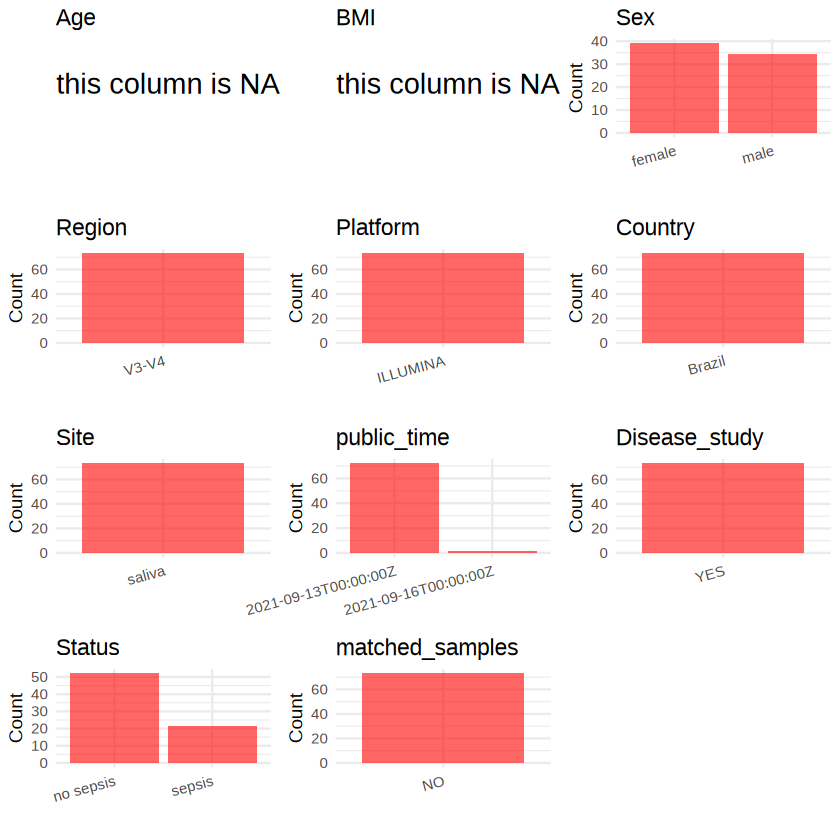

In [8]:
plot_data <- uniform_meta %>%
  select(-BioProject, -Run, -sample_name, -title)

create_simple_plots <- function(data) {
  plots <- list()
  
  for (col in colnames(data)) {
    if (all(is.na(data[[col]]))) {
      p <- ggplot() +
        annotate("text", x = 0.5, y = 0.5, label = "this column is NA", size = 6) +
        labs(title = col) +
        theme_void()
    } else if (is.numeric(data[[col]])) {
      p <- ggplot(data, aes(x = .data[[col]])) +
        geom_histogram(fill = "blue", alpha = 0.6, bins = 20, na.rm = TRUE) +
        labs(title = col) +
        theme_minimal()
    } else {
      count_data <- as.data.frame(table(data[[col]], useNA = "ifany"))
      p <- ggplot(count_data, aes(x = reorder(Var1, -Freq), y = Freq)) +
        geom_col(fill = "red", alpha = 0.6) +
        labs(title = col, x = NULL, y = "Count") +
        theme_minimal() +
        theme(axis.text.x = element_text(angle = 15, hjust = 1))
    }
    plots[[col]] <- p
  }
  return(plots)
}

plots <- create_simple_plots(plot_data)
p<-plot_grid(plots$Age, 
          plots$BMI, 
          plots$Sex, 
          plots$Region, 
          plots$Platform, 
          plots$Country, 
          plots$Site,
          plots$public_time, 
          #plots$PCR_primers,
          plots$Disease_study,
          plots$Status,
          plots$matched_samples,# add 
          ncol = 3, align = "hv", axis = "lb")
p

In [9]:
uniform_meta <- uniform_meta[, c("BioProject", "Run", "sample_name", "Age", "BMI", "Sex", "Region", "Platform", "Country", "Site", "public_time", "PCR_primers", "title", "Disease_study", "Status")]
write.csv(uniform_meta, file = "/home/liuxuan/metadata/10-10/PRJNA762545/metadata.csv", quote = T)